# UCS420 Lab Assignment 9 — NLP Text Preprocessing
Enter your roll number and name, then run all cells.

In [ ]:
ROLL_NO = 1024170386        # <-- your full roll number
NAME = "Drig Bajaj"            # <-- your name

import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)
assert ROLL_NO > 0 and NAME, "Enter your roll number and name first"

### Dataset generator — do not modify

In [ ]:
import random, hashlib
import pandas as pd

def generate_dataset(roll_no):
    """Return (DataFrame of tickets, focus ticket IDs, fingerprint) for a roll number. Do not modify."""
    rng = random.Random(int(roll_no))

    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }

    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)

    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint

### Preprocessing pipeline — do not modify

In [ ]:
import string
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))

def is_punct(token):
    """A token is punctuation if EVERY character in it is in string.punctuation (e.g. '.', '...', '``', "''")."""
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    """The official pipeline. Returns sentences, lowercase tokens, punctuation, stopwords and final tokens."""
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}

In [ ]:
df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Roll number: {ROLL_NO}   Name: {NAME}   Fingerprint: {FINGERPRINT}   Tickets: {len(df)}\n")
print(df.to_string(index=False))
df.to_csv(f"{ROLL_NO}_generated_dataset.csv", index=False)

Roll number: 1024170386   Name: Drig Bajaj   Fingerprint: 47BD54D6   Tickets: 13

Ticket_ID                                                                  Ticket_Text
      T01       Printer keeps asking for login when I use mobile hotspot. Please help.
      T02                     The projector failed to open. I don't know what changed.
      T03                              The password is running slowly. This is urgent.
      T04                                        I need Windows 11 by 5.30 p.m. today.
      T05       I reinstalled the e-mail while uploading the file. Can you check this?
      T06                               Re-installing didn't help; log-in still fails!
      T07 Server keeps asking for login since yesterday. It works on another computer.
      T08                                                  My roll no. is 1023-03-021.
      T09  I was locked out of the projector on my laptop. I have tried several times!
      T10                     Wi-Fi failed to op

---
## Q1. Preprocessing pipeline
Run process_ticket() on every ticket and show one table with, per ticket: sentences, tokens, punctuation tokens, stopwords, unique tokens and final tokens, plus a TOTAL row.

In [ ]:
# Process every ticket from the generated DataFrame
processed_data = []

for _, row in df.iterrows():
    result = process_ticket(row["Ticket_Text"])

    processed_data.append({
        "Ticket_ID": row["Ticket_ID"],
        "Number of Sentences": len(result["sentences"]),
        "Number of Tokens": len(result["tokens"]),
        "Number of Punctuation Tokens": len(result["punct"]),
        "Number of Stopwords": len(result["stops"]),
        "Number of Unique Tokens": len(set(result["tokens"])),
        "Number of Final Tokens": len(result["final"])
    })

# Create summary table
summary_df = pd.DataFrame(processed_data)

# Add total row
total = {
    "Ticket_ID": "TOTAL",
    "Number of Sentences": summary_df["Number of Sentences"].sum(),
    "Number of Tokens": summary_df["Number of Tokens"].sum(),
    "Number of Punctuation Tokens": summary_df["Number of Punctuation Tokens"].sum(),
    "Number of Stopwords": summary_df["Number of Stopwords"].sum(),
    "Number of Unique Tokens": summary_df["Number of Unique Tokens"].sum(),
    "Number of Final Tokens": summary_df["Number of Final Tokens"].sum()
}

summary_df = pd.concat(
    [summary_df, pd.DataFrame([total])],
    ignore_index=True
)

# Display the table
display(summary_df)

# Display details for one selected ticket
selected_id = "T01"
selected_text = df.loc[df["Ticket_ID"] == selected_id, "Ticket_Text"].iloc[0]
result = process_ticket(selected_text)

print(f"\nDetails of {selected_id}:")
print("\nActual Tokens:")
print(result["tokens"])

print("\nPunctuation Tokens:")
print(result["punct"])

print("\nStopwords:")
print(result["stops"])

print("\nFinal Tokens:")
print(result["final"])

,Ticket_ID,Number of Sentences,Number of Tokens,Number of Punctuation Tokens,Number of Stopwords,Number of Unique Tokens,Number of Final Tokens
0,T01,2,14,2,3,13,9
1,T02,2,13,2,5,12,6
2,T03,2,10,2,4,8,4
3,T04,1,9,1,2,9,6
4,T05,2,14,2,7,13,5
5,T06,1,9,2,1,9,6
6,T07,2,14,2,3,13,9
7,T08,2,7,2,3,6,2
8,T09,2,17,2,9,16,6
9,T10,2,11,2,2,10,7



Details of T01:

Actual Tokens:
['printer', 'keeps', 'asking', 'for', 'login', 'when', 'i', 'use', 'mobile', 'hotspot', '.', 'please', 'help', '.']

Punctuation Tokens:
['.', '.']

Stopwords:
['for', 'when', 'i']

Final Tokens:
['printer', 'keeps', 'asking', 'login', 'use', 'mobile', 'hotspot', 'please', 'help']


**Observe:** Which final tokens in your data are not real words (e.g. n't, 's, ca)? Where do they come from?

*Your answer:* The final tokens that are not real standalone words include tokens such as **ca**, **n't**, and **'s**. They come from the **word_tokenize()** step, which splits contractions and possessive forms into separate tokens. For example, **“can't”** is split into **ca + n't**, **“didn't”** into **did + n't**, and **“Rao's”** into **Rao + 's**. These tokens remain in the final tokens because they are neither punctuation tokens nor stopwords.

---
## Q2. Regular expressions
On your raw tickets, use re.findall to extract: words longer than 5 letters; all numbers (keep 95.5 and 2.0.1 whole); capitalized words; words starting with a vowel. Then use re.sub to replace emails with <EMAIL>, URLs with <URL> and phone numbers with <PHONE>. Your patterns must also work on TEST_LINES (given in the notebook).

In [ ]:
TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.",
]

import re

# Regex patterns
long_words = r"\b[A-Za-z]{6,}\b"

# Matches integers, decimals and version numbers
numbers = r"\b\d+(?:\.\d+)*\b"

# Words beginning with a capital letter
capitalized = r"\b[A-Z][A-Za-z]*\b"

# Words beginning with a vowel
vowel_words = r"\b[AEIOUaeiou][A-Za-z]*\b"

# Email addresses
email = r"\b[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}\b"

# URLs
url = r"https?://[^\s]+|www\.[^\s]+"

# Indian phone numbers
phone = r"(?:\+91[\s-]?)?\d{5}[\s-]\d{5}|\b\d{4}-\d{3}-\d{4}\b"


# ---------- RAW TICKETS ----------

for _, row in df.iterrows():
    text = row["Ticket_Text"]

    print(f"\n{row['Ticket_ID']}: {text}")

    print("Words > 5 letters:",
          re.findall(long_words, text))

    print("Numbers:",
          re.findall(numbers, text))

    print("Capitalized words:",
          re.findall(capitalized, text))

    print("Words starting with vowel:",
          re.findall(vowel_words, text))

    # Replacement
    replaced = re.sub(email, "<EMAIL>", text)
    replaced = re.sub(url, "<URL>", replaced)
    replaced = re.sub(phone, "<PHONE>", replaced)

    print("After replacement:", replaced)


# ---------- TEST_LINES ----------

print("\n" + "=" * 50)
print("TEST_LINES")
print("=" * 50)

for line in TEST_LINES:

    print("\nOriginal:", line)

    print("Words > 5 letters:",
          re.findall(long_words, line))

    print("Numbers:",
          re.findall(numbers, line))

    print("Capitalized words:",
          re.findall(capitalized, line))

    print("Words starting with vowel:",
          re.findall(vowel_words, line))

    replaced = re.sub(email, "<EMAIL>", line)
    replaced = re.sub(url, "<URL>", replaced)
    replaced = re.sub(phone, "<PHONE>", replaced)

    print("After replacement:", replaced)


T01: Printer keeps asking for login when I use mobile hotspot. Please help.
Words > 5 letters: ['Printer', 'asking', 'mobile', 'hotspot', 'Please']
Numbers: []
Capitalized words: ['Printer', 'I', 'Please']
Words starting with vowel: ['asking', 'I', 'use']
After replacement: Printer keeps asking for login when I use mobile hotspot. Please help.

T02: The projector failed to open. I don't know what changed.
Words > 5 letters: ['projector', 'failed', 'changed']
Numbers: []
Capitalized words: ['The', 'I']
Words starting with vowel: ['open', 'I']
After replacement: The projector failed to open. I don't know what changed.

T03: The password is running slowly. This is urgent.
Words > 5 letters: ['password', 'running', 'slowly', 'urgent']
Numbers: []
Capitalized words: ['The', 'This']
Words starting with vowel: ['is', 'is', 'urgent']
After replacement: The password is running slowly. This is urgent.

T04: I need Windows 11 by 5.30 p.m. today.
Words > 5 letters: ['Windows']
Numbers: ['11', '5.

**Observe:** How many of your capitalized words are capitalized only because they start a sentence?

*Your answer:* There are 17 capitalized words that are capitalized only because they occur at the beginning of a sentence. These include words such as **Printer, Please, The, This, Can, Server, It, My, Re and The**. The other capitalized words, such as **I, Windows, LMS and Wi-Fi** are capitalized for reasons other than simply starting a sentence.

---
## Q3. Custom tokenizer
Write my_tokenize(text) with one RegexpTokenizer pattern that keeps contractions (isn't), hyphenated words (Wi-Fi, state-of-the-art), decimals and versions (95.5, 2.0.1), emails, URLs and phone numbers as single tokens. Run it on TEST_LINES and on your tickets, and compare with word_tokenize.

In [ ]:
from nltk.tokenize import RegexpTokenizer, word_tokenize

# One regex pattern for all required token types
pattern = r"""
https?://[^\s]+
|www\.[^\s]+
|[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}
|\+91[-\s]?\d{5}[-\s]?\d{5}
|\d{4}-\d{3}-\d{4}
|\d+(?:\.\d+)+
|\d+\.\d+
|[A-Za-z]+(?:-[A-Za-z]+)+
|[A-Za-z]+(?:'[A-Za-z]+)?
"""

tokenizer = RegexpTokenizer(pattern, flags=0 |  re.VERBOSE)

def my_tokenize(text):
    return tokenizer.tokenize(text)


# ---------- TEST_LINES ----------

print("========== TEST_LINES ==========")

for i, line in enumerate(TEST_LINES, 1):
    print(f"\nTEST_LINE {i}")
    print("Original:", line)
    print("My tokenizer:", my_tokenize(line))
    print("word_tokenize:", word_tokenize(line))


# ---------- GENERATED TICKETS ----------

print("\n\n========== GENERATED TICKETS ==========")

for _, row in df.iterrows():
    text = row["Ticket_Text"]

    print(f"\n{row['Ticket_ID']}: {text}")
    print("My tokenizer :", my_tokenize(text))
    print("word_tokenize:", word_tokenize(text))

========== TEST_LINES ==========

TEST_LINE 1
Original: Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
My tokenizer: ['Mail', 'it.helpdesk@thapar.edu', 'or', 'a.b-c@dept.univ.ac.in', 'visit', 'https://lms.thapar.edu/help', 'or', 'www.thapar.edu/it.']
word_tokenize: ['Mail', 'it.helpdesk', '@', 'thapar.edu', 'or', 'a.b-c', '@', 'dept.univ.ac.in', ';', 'visit', 'https', ':', '//lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']

TEST_LINE 2
Original: Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
My tokenizer: ['Call', '+91 98765 43210', '+91-98765-43210', 'or', '0175-239-3201', 'Version', '2.0.1', 'is', '95.5', 'done', 'fee', 'Rs']
word_tokenize: ['Call', '+91', '98765', '43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']

TEST_LINE 3
Original: The state-of-the-art lab isn't open; log

**Observe:** How many of your tickets are tokenized differently by my_tokenize and word_tokenize?

*Your answer:* All 13 tickets are tokenized differently by my_tokenize() and word_tokenize().
Some important differences are:

**1. Contractions:**

word_tokenize() → isn, 't

my_tokenize() → isn't

**2. Hyphenated words:**

word_tokenize() → state, -, of, -, the, -, art

my_tokenize() → state-of-the-art

**3. Decimals and versions:**
word_tokenize() may split 95.5 or 2.0.1 around the periods, while my_tokenize() keeps them as single tokens: 95.5, 2.0.1.

**4. Email addresses:**
word_tokenize() splits an email such as it.helpdesk@thapar.edu into multiple tokens, whereas my_tokenize() keeps the complete email as one token.

**5. URLs:**
word_tokenize() splits a URL such as https://lms.thapar.edu/help, while my_tokenize() keeps the complete URL as one token.

**6. Phone numbers:**
word_tokenize() can split +91-98765-43210 around the + and hyphens, whereas my_tokenize() keeps the complete phone number as one token.

---
## Q4. Stemming and lemmatization
On your unique final tokens, compare PorterStemmer, LancasterStemmer, a RegexpStemmer with a suffix rule you choose after looking at your own words, and WordNetLemmatizer with POS tags from nltk.pos_tag. Show a table of the words where the outputs differ.

In [ ]:
import re
import pandas as pd
import nltk

from nltk.stem import PorterStemmer, LancasterStemmer, RegexpStemmer, WordNetLemmatizer
from nltk import pos_tag
from nltk.corpus import wordnet

# Download required resources
nltk.download("wordnet")
nltk.download("omw-1.4")
nltk.download("averaged_perceptron_tagger")
nltk.download("averaged_perceptron_tagger_eng")

# --------------------------------------------------
# 1. Get unique final tokens from all tickets
# --------------------------------------------------

all_final_tokens = []

for _, row in df.iterrows():
    result = process_ticket(row["Ticket_Text"])
    all_final_tokens.extend(result["final"])

unique_tokens = sorted(set(all_final_tokens))

# --------------------------------------------------
# 2. Choose a suffix for RegexpStemmer
# --------------------------------------------------
# Dataset words such as "working", "uploading",
# "reinstalling", "showing", "running" contain -ing.

regexp_stemmer = RegexpStemmer(r"ing$", min=3)

# --------------------------------------------------
# 3. POS conversion for WordNet
# --------------------------------------------------

def get_wordnet_pos(tag):
    if tag.startswith("J"):
        return wordnet.ADJ
    elif tag.startswith("V"):
        return wordnet.VERB
    elif tag.startswith("N"):
        return wordnet.NOUN
    elif tag.startswith("R"):
        return wordnet.ADV
    else:
        return wordnet.NOUN

# POS tag all unique tokens
pos_tags = dict(pos_tag(unique_tokens))

# --------------------------------------------------
# 4. Apply all four methods
# --------------------------------------------------

porter = PorterStemmer()
lancaster = LancasterStemmer()
lemmatizer = WordNetLemmatizer()

results = []

for word in unique_tokens:

    porter_result = porter.stem(word)
    lancaster_result = lancaster.stem(word)
    regexp_result = regexp_stemmer.stem(word)

    pos = get_wordnet_pos(pos_tags[word])
    lemma_result = lemmatizer.lemmatize(word, pos=pos)

    # Keep only words where outputs differ
    if len({porter_result, lancaster_result,
            regexp_result, lemma_result}) > 1:

        results.append({
            "Word": word,
            "Porter": porter_result,
            "Lancaster": lancaster_result,
            "Regexp": regexp_result,
            "WordNet Lemma": lemma_result
        })

# --------------------------------------------------
# 5. Display comparison table
# --------------------------------------------------

comparison_df = pd.DataFrame(results)

display(comparison_df)

[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     /root/nltk_data...
[nltk_data]   Package averaged_perceptron_tagger is already up-to-
[nltk_data]       date!
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     /root/nltk_data...
[nltk_data]   Package averaged_perceptron_tagger_eng is already up-to-
[nltk_data]       date!


,Word,Porter,Lancaster,Regexp,WordNet Lemma
0,another,anoth,anoth,another,another
1,anything,anyth,anyth,anyth,anything
2,change,chang,chang,change,change
3,changed,chang,chang,changed,change
4,computer,comput,comput,computer,computer
5,error,error,er,error,error
6,failed,fail,fail,failed,fail
7,fails,fail,fail,fails,fails
8,file,file,fil,file,file
9,keeps,keep,keep,keeps,keep


**Observe:** Give one over-stemming and one under-stemming example from your table.

*Your answer:* **Over-stemming:** running → runn using the Regexp Stemmer. It removes the -ing suffix mechanically and produces runn, which is not a proper stem.

**Under-stemming:** failed → failed using the Regexp Stemmer, while the WordNet lemmatizer gives fail. The suffix rule does not remove -ed, so the word is not reduced to its base form.

---
## Q5. Corpus statistics
Compute tokens, unique tokens and TTR for S1 (all tokens), S2 (no punctuation), S3 (final tokens) and S4 (S3 after Porter). Print the top 10 words of S1 and S3, plot log(rank) vs log(frequency) for S3, and print the top 5 bigrams of S1 and S3.

CORPUS STATISTICS


,Set,Total Tokens,Unique Tokens,TTR
0,S1,154,88,0.5714
1,S2,130,84,0.6462
2,S3,77,58,0.7532
3,S4,77,55,0.7143



TOP 10 WORDS OF S1
[('.', 20), ('i', 8), ('the', 8), ("n't", 4), ('is', 4), ('login', 3), ('yesterday', 3), ('it', 3), ('on', 3), ('keeps', 2)]

TOP 10 WORDS OF S3
[("n't", 4), ('login', 3), ('yesterday', 3), ('keeps', 2), ('asking', 2), ('please', 2), ('help', 2), ('projector', 2), ('failed', 2), ('open', 2)]


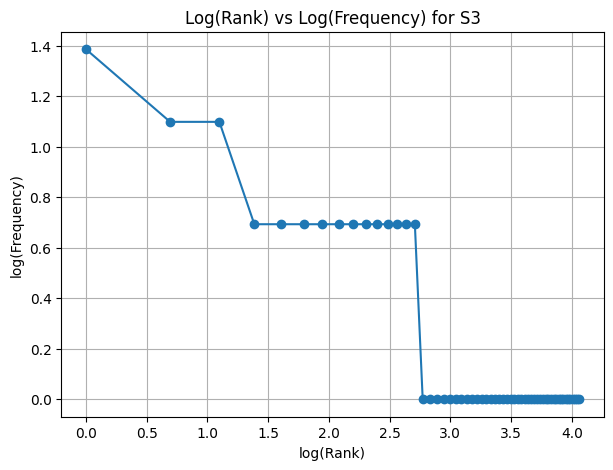


TOP 5 BIGRAMS OF S1
[(('.', 'i'), 6), (('.', 'the'), 5), (('yesterday', '.'), 3), (('keeps', 'asking'), 2), (('asking', 'for'), 2)]

TOP 5 BIGRAMS OF S3
[(('keeps', 'asking'), 2), (('asking', 'login'), 2), (('failed', 'open'), 2), (('since', 'yesterday'), 2), (('works', 'another'), 2)]


In [ ]:
import math
import matplotlib.pyplot as plt
from collections import Counter
from nltk.stem import PorterStemmer

# -----------------------------------------
# Create S1, S2, S3 and S4
# -----------------------------------------

S1 = []
S2 = []
S3 = []

for _, row in df.iterrows():
    result = process_ticket(row["Ticket_Text"])

    # S1: all tokens
    S1.extend(result["tokens"])

    # S2: tokens without punctuation
    S2.extend([t for t in result["tokens"] if t not in result["punct"]])

    # S3: final tokens
    S3.extend(result["final"])

# S4: Porter-stemmed S3
porter = PorterStemmer()
S4 = [porter.stem(word) for word in S3]


# -----------------------------------------
# Corpus statistics
# -----------------------------------------

def corpus_stats(tokens):
    total = len(tokens)
    unique = len(set(tokens))
    ttr = unique / total if total > 0 else 0
    return total, unique, ttr

stats = []

for name, tokens in [("S1", S1), ("S2", S2), ("S3", S3), ("S4", S4)]:
    total, unique, ttr = corpus_stats(tokens)

    stats.append({
        "Set": name,
        "Total Tokens": total,
        "Unique Tokens": unique,
        "TTR": round(ttr, 4)
    })

stats_df = pd.DataFrame(stats)

print("CORPUS STATISTICS")
display(stats_df)


# -----------------------------------------
# Top 10 words of S1 and S3
# -----------------------------------------

print("\nTOP 10 WORDS OF S1")
print(Counter(S1).most_common(10))

print("\nTOP 10 WORDS OF S3")
print(Counter(S3).most_common(10))


# -----------------------------------------
# Log(rank) vs Log(frequency) for S3
# -----------------------------------------

frequency = Counter(S3)
sorted_freq = sorted(frequency.values(), reverse=True)

ranks = range(1, len(sorted_freq) + 1)

log_rank = [math.log(r) for r in ranks]
log_frequency = [math.log(f) for f in sorted_freq]

plt.figure(figsize=(7, 5))
plt.plot(log_rank, log_frequency, marker="o")
plt.xlabel("log(Rank)")
plt.ylabel("log(Frequency)")
plt.title("Log(Rank) vs Log(Frequency) for S3")
plt.grid(True)
plt.show()


# -----------------------------------------
# Top 5 bigrams of S1 and S3
# -----------------------------------------

def get_bigrams(tokens):
    return list(zip(tokens[:-1], tokens[1:]))

S1_bigrams = Counter(get_bigrams(S1))
S3_bigrams = Counter(get_bigrams(S3))

print("\nTOP 5 BIGRAMS OF S1")
print(S1_bigrams.most_common(5))

print("\nTOP 5 BIGRAMS OF S3")
print(S3_bigrams.most_common(5))

**Observe:** Why does TTR change from S1 to S4 in your data?

*Your answer:* TTR changes from S1 to S4 because preprocessing gradually reduces the number of different word forms. In S1, all tokens, including punctuation and stopwords, are present. After removing punctuation and stopwords, S3 has fewer tokens. In S4, Porter stemming combines different forms of the same word, such as working, worked, and works into similar stems. Therefore, the number of unique tokens decreases relative to the total tokens, causing the TTR to change.

# Q6. Interpretation

**(a) Why does TTR change from S1 to S4 in your dataset?**

TTR changes because preprocessing removes punctuation and stopwords, and stemming combines different word forms into common stems. This reduces the number of unique tokens relative to the total number of tokens.

**b) Give one example where word_tokenize() and your tokenizer differ. Explain the difference.**

For “isn't”, word_tokenize() produces isn and 't, while my tokenizer keeps isn't as one token. My tokenizer is designed to preserve contractions because they represent a single meaningful word.

**(c) Give one example where stemming produces an undesirable result.**

For “running”, the Regexp Stemmer with the -ing rule produces runn, which is not a proper English word. This is an example of over-stemming.

**(d) Give one example where POS-aware lemmatization preserves meaning better than stemming.**

For “was”, POS-aware lemmatization can produce be, which is the correct base form of the verb. Stemming may produce a less meaningful form depending on the stemmer. Thus, POS-aware lemmatization uses grammatical information to produce a meaningful dictionary form.